In [13]:
import pandas as pd
print(pd.__version__)

3.1.1


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.DataFrame({
    'source': [
        'Cauvery Stages I-IV',
        'Cauvery Stage V (actual)',
        'Groundwater extraction',
        'Total demand',
        'Wastewater generated'
    ],
    'mld': [1460, 400, 1372, 2632, 1940]
})
df

,source,mld
0,Cauvery Stages I-IV,1460
1,Cauvery Stage V (actual),400
2,Groundwater extraction,1372
3,Total demand,2632
4,Wastewater generated,1940


In [16]:
df.shape

(5, 2)

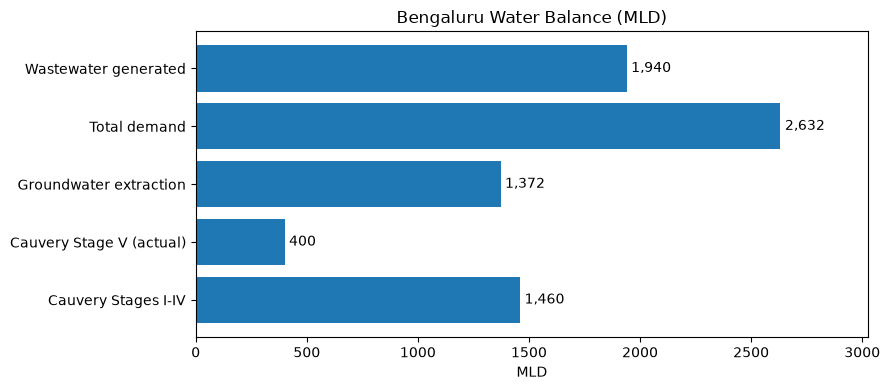

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(df['source'], df['mld'])

for bar, val in zip(bars, df['mld']):
    ax.text(
        bar.get_width() + 20, bar.get_y() + bar.get_height() / 2,
        f'{val:,}', va='center', fontsize=10
    )

ax.set_xlabel('MLD')
ax.set_title('Bengaluru Water Balance (MLD)')
ax.set_xlim(0, df['mld'].max() * 1.15)
plt.tight_layout()
plt.show()

In [18]:
data = df.set_index('source')['mld']

cauvery_supply = data['Cauvery Stages I-IV'] + data['Cauvery Stage V (actual)']
gap = data['Total demand'] - cauvery_supply
gap_percent = (gap / data['Total demand']) * 100
groundwater_percent = (data['Groundwater extraction'] / data['Total demand']) * 100

print(f'Cauvery supply: {cauvery_supply} MLD')
print(f'Gap: {gap} MLD')
print(f'Gap percent: {gap_percent:.1f}%')
print(f'Groundwater percent: {groundwater_percent:.1f}%')

Cauvery supply: 1860 MLD
Gap: 772 MLD
Gap percent: 29.3%
Groundwater percent: 52.1%
